# Genetic Algorithm for EV Charging Optimization
Optimize an overnight EV charging schedule to **minimize electricity cost** and **battery stress** (high C-rate, staying at high SoC) while making sure the car hits the **target battery level** before departure.

Follows the 9 steps: define problem → parameters → initial population → fitness → selection → crossover → mutation → iteration → best solution.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

## Step 1: Define the Problem

In [2]:
CAP        = 40.0
SOC_INIT   = 0.20
SOC_TARGET = 0.90
SOC_MAX    = 1.00
SOC_HIGH   = 0.80
EFF        = 0.92
DT         = 1.0

POWER_LEVELS = np.array([0, 1.85, 3.70, 5.55, 7.40])

HOURS  = [18,19,20,21,22,23,0,1,2,3,4,5,6,7]
PRICES = np.array([9.5,9.5,9.5,9.5, 6.5, 4.5,4.5,4.5,4.5,4.5,4.5,4.5, 6.5,6.5])
N_SLOTS = len(HOURS)

DEG_COEF_CRATE = 5.0
DEG_COEF_HIGH  = 20.0
UNMET_PENALTY  = 20.0


def simulate(ind):
    soc, cost, deg = SOC_INIT, 0.0, 0.0
    soc_trace, power_trace = [soc], []
    for gene, price in zip(ind, PRICES):
        p = POWER_LEVELS[gene]
        e_batt = min(p * EFF * DT, (SOC_MAX - soc) * CAP)
        e_grid = e_batt / EFF
        p_eff  = e_grid / DT
        cost += e_grid * price
        deg  += e_batt * (DEG_COEF_CRATE * (p_eff / CAP) + DEG_COEF_HIGH * max(0, soc - SOC_HIGH))
        soc  += e_batt / CAP
        soc_trace.append(soc)
        power_trace.append(p_eff)
    return cost, deg, soc, soc_trace, power_trace

## Step 2: Initialize Parameters

In [3]:
POP_SIZE        = 100
N_GENERATIONS   = 200
CROSSOVER_RATE  = 0.85
MUTATION_RATE   = 0.08
TOURNAMENT_K    = 3
ELITISM         = 2
N_LEVELS        = len(POWER_LEVELS)

## Step 3: Create Initial Population
Each individual = list of 14 integers (power level per hour).

In [4]:
def create_individual():
    return [random.randint(0, N_LEVELS - 1) for _ in range(N_SLOTS)]

def create_population(size):
    return [create_individual() for _ in range(size)]

## Step 4: Evaluate Fitness
GA maximizes fitness, so fitness = −(cost + battery degradation + unmet-target penalty).

In [5]:
def fitness(ind):
    cost, deg, final_soc, _, _ = simulate(ind)
    shortfall_pct = max(0.0, SOC_TARGET - final_soc) * 100
    return -(cost + deg + UNMET_PENALTY * shortfall_pct)

## Step 5: Selection (Tournament)

In [6]:
def tournament_selection(pop, fits):
    contenders = random.sample(range(len(pop)), TOURNAMENT_K)
    winner = max(contenders, key=lambda i: fits[i])
    return pop[winner][:]

## Step 6: Crossover (Two-point)

In [7]:
def crossover(p1, p2):
    if random.random() > CROSSOVER_RATE:
        return p1[:], p2[:]
    a, b = sorted(random.sample(range(1, N_SLOTS), 2))
    c1 = p1[:a] + p2[a:b] + p1[b:]
    c2 = p2[:a] + p1[a:b] + p2[b:]
    return c1, c2

## Step 7: Mutation
Each gene either gets a random new level or nudges ±1 level.

In [8]:
def mutate(ind):
    for i in range(N_SLOTS):
        if random.random() < MUTATION_RATE:
            if random.random() < 0.5:
                ind[i] = random.randint(0, N_LEVELS - 1)
            else:
                ind[i] = min(N_LEVELS - 1, max(0, ind[i] + random.choice([-1, 1])))
    return ind

## Step 8: Iteration (Main GA Loop)

In [9]:
def run_ga():
    pop = create_population(POP_SIZE)
    best_hist, avg_hist = [], []
    best_ind, best_fit = None, -np.inf

    for gen in range(N_GENERATIONS):
        fits = [fitness(ind) for ind in pop]

        gi = int(np.argmax(fits))
        if fits[gi] > best_fit:
            best_fit, best_ind = fits[gi], pop[gi][:]
        best_hist.append(best_fit)
        avg_hist.append(np.mean(fits))

        order = np.argsort(fits)[::-1]
        new_pop = [pop[i][:] for i in order[:ELITISM]]

        while len(new_pop) < POP_SIZE:
            p1 = tournament_selection(pop, fits)
            p2 = tournament_selection(pop, fits)
            c1, c2 = crossover(p1, p2)
            new_pop.append(mutate(c1))
            if len(new_pop) < POP_SIZE:
                new_pop.append(mutate(c2))
        pop = new_pop

        if gen % 25 == 0 or gen == N_GENERATIONS - 1:
            print(f"Gen {gen:3d} | best fitness {best_fit:8.2f} | avg {avg_hist[-1]:8.2f}")

    return best_ind, best_fit, best_hist, avg_hist

best_ind, best_fit, best_hist, avg_hist = run_ga()

Gen   0 | best fitness  -194.22 | avg  -270.04
Gen  25 | best fitness  -161.60 | avg  -203.83
Gen  50 | best fitness  -158.45 | avg  -189.25
Gen  75 | best fitness  -158.45 | avg  -187.43
Gen 100 | best fitness  -158.45 | avg  -181.63
Gen 125 | best fitness  -158.45 | avg  -185.90
Gen 150 | best fitness  -158.45 | avg  -187.92
Gen 175 | best fitness  -158.45 | avg  -194.47
Gen 199 | best fitness  -158.45 | avg  -186.56


## Step 9: Output the Best Solution

In [10]:
cost, deg, final_soc, soc_trace, power_trace = simulate(best_ind)

print("Best schedule (hour -> kW):")
for h, p, price in zip(HOURS, power_trace, PRICES):
    print(f"  {h:02d}:00  {p:5.2f} kW   (Rs {price}/kWh)")
print(f"\nEnergy cost        : Rs {cost:.2f}")
print(f"Degradation penalty: {deg:.2f}")
print(f"Final SoC          : {final_soc*100:.1f}%  (target {SOC_TARGET*100:.0f}%)")
print(f"Best fitness       : {best_fit:.2f}")

naive = [N_LEVELS - 1] * N_SLOTS
n_cost, n_deg, n_soc, n_soc_trace, n_power = simulate(naive)
print(f"\nBaseline (max power from 18:00): cost Rs {n_cost:.2f}, degradation {n_deg:.2f}, final SoC {n_soc*100:.1f}%")
print(f"Cost saving vs baseline: Rs {n_cost - cost:.2f} ({(n_cost-cost)/n_cost*100:.1f}%)")

Best schedule (hour -> kW):
  18:00   0.00 kW   (Rs 9.5/kWh)
  19:00   0.00 kW   (Rs 9.5/kWh)
  20:00   0.00 kW   (Rs 9.5/kWh)
  21:00   0.00 kW   (Rs 9.5/kWh)
  22:00   0.00 kW   (Rs 6.5/kWh)
  23:00   3.70 kW   (Rs 4.5/kWh)
  00:00   3.70 kW   (Rs 4.5/kWh)
  01:00   5.55 kW   (Rs 4.5/kWh)
  02:00   5.55 kW   (Rs 4.5/kWh)
  03:00   3.70 kW   (Rs 4.5/kWh)
  04:00   3.70 kW   (Rs 4.5/kWh)
  05:00   5.55 kW   (Rs 4.5/kWh)
  06:00   0.00 kW   (Rs 6.5/kWh)
  07:00   0.00 kW   (Rs 6.5/kWh)

Energy cost        : Rs 141.53
Degradation penalty: 16.92
Final SoC          : 92.3%  (target 90%)
Best fitness       : -158.45

Baseline (max power from 18:00): cost Rs 314.89, degradation 35.98, final SoC 100.0%
Cost saving vs baseline: Rs 173.36 (55.1%)


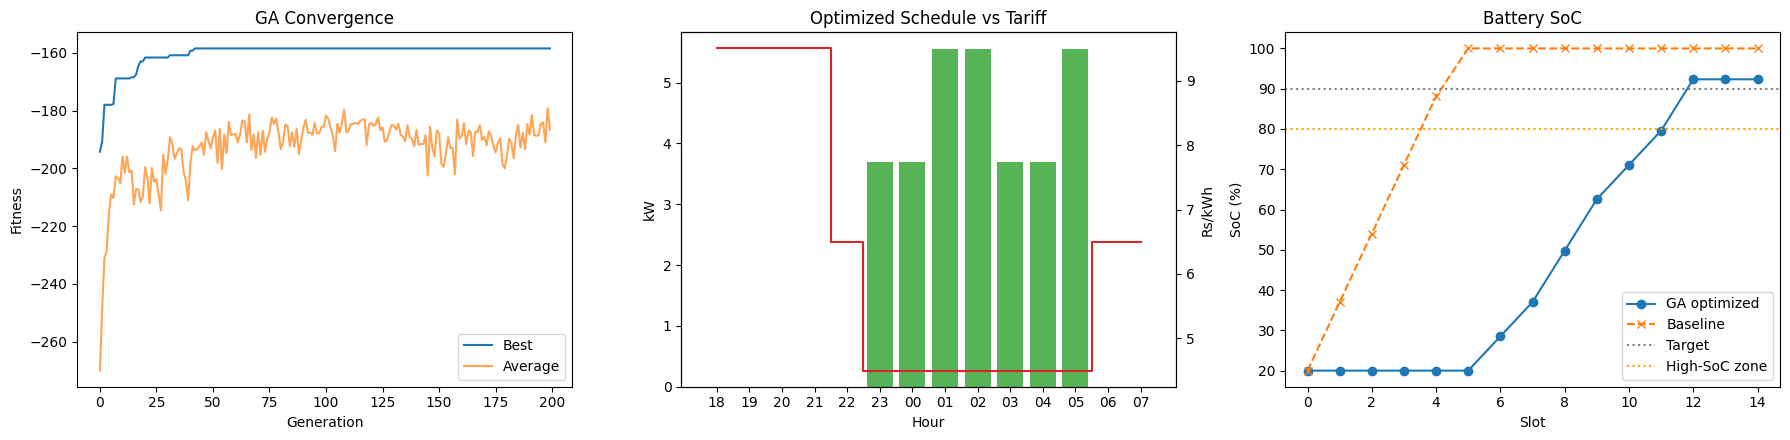

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].plot(best_hist, label="Best")
ax[0].plot(avg_hist, label="Average", alpha=0.7)
ax[0].set_title("GA Convergence"); ax[0].set_xlabel("Generation"); ax[0].set_ylabel("Fitness"); ax[0].legend()

x = range(N_SLOTS)
ax[1].bar(x, power_trace, color="tab:green", alpha=0.8, label="Charging power (kW)")
ax[1].set_xticks(list(x)); ax[1].set_xticklabels([f"{h:02d}" for h in HOURS])
ax[1].set_xlabel("Hour"); ax[1].set_ylabel("kW")
ax1b = ax[1].twinx()
ax1b.step(x, PRICES, where="mid", color="tab:red", label="Price (Rs/kWh)")
ax1b.set_ylabel("Rs/kWh")
ax[1].set_title("Optimized Schedule vs Tariff")

ax[2].plot(np.array(soc_trace)*100, marker="o", label="GA optimized")
ax[2].plot(np.array(n_soc_trace)*100, marker="x", linestyle="--", label="Baseline")
ax[2].axhline(SOC_TARGET*100, color="gray", linestyle=":", label="Target")
ax[2].axhline(SOC_HIGH*100, color="orange", linestyle=":", label="High-SoC zone")
ax[2].set_title("Battery SoC"); ax[2].set_xlabel("Slot"); ax[2].set_ylabel("SoC (%)"); ax[2].legend()

plt.tight_layout(); plt.show()